# Семестровая работа по введению в Машинное обучение
## Выполнил Цвиль Павел, группа ФИТ-231

## 1. Загрузка и первичный анализ

Загружаем датасет. Смотрим на типы данных и пропуски. 
Выводим описательную статистику.

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка
df = pd.read_csv('data/dataset_var8.csv', sep=';', header=None)
df.columns = [f'f{i}' for i in range(df.shape[1] - 1)] + ['y']

print('Размер датасета:', df.shape)
print('\nТипы данных и пропуски:')
print(df.info())

# Описательная статистика
display(df.describe())

# Смотрим на пропуски
print('\nКоличество пропусков в столбцах:')
print(df.isna().sum())

Размер датасета: (100, 8)

Типы данных и пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f0      100 non-null    float64
 1   f1      100 non-null    float64
 2   f2      100 non-null    float64
 3   f3      100 non-null    float64
 4   f4      95 non-null     float64
 5   f5      30 non-null     float64
 6   f6      100 non-null    float64
 7   y       100 non-null    float64
dtypes: float64(8)
memory usage: 6.4 KB
None


,f0,f1,f2,f3,f4,f5,f6,y
count,100.000000,100.000000,100.000000,100.000000,95.000000,30.000000,100.000000,100.000000
mean,-0.015087,-0.062730,0.060476,0.022940,0.009851,0.138701,0.062513,1.171854
std,1.079071,0.884791,2.275398,0.934232,1.022725,0.915934,1.002306,72.479434
min,-4.088452,-1.921410,-14.212845,-2.359941,-2.418926,-1.950182,-2.309040,-241.733235
25%,-0.594173,-0.728709,-0.699190,-0.503863,-0.748278,-0.402404,-0.633906,-47.991266
50%,0.060166,-0.048621,0.156478,0.031870,0.032623,0.268823,0.069673,4.931790
75%,0.476788,0.474352,0.820545,0.666486,0.664160,0.590084,0.673443,40.368420
max,2.661735,2.528793,12.410108,2.409821,2.634238,2.361355,2.669669,168.456399



Количество пропусков в столбцах:
f0     0
f1     0
f2     0
f3     0
f4     5
f5    70
f6     0
y      0
dtype: int64


### Выводы по действию:

Увидел информацию по таблице (среднее, стандартное отклонение, мин, макс, медиану и квартили)

Заметил, что в ф4 пропущенно 5 значений, а в ф5 аж 70

## 2. Корреляционный анализ (предварительный)

Перед тем как обрабатывать пропуски, оценю корреляцию признаков с целевой переменной

Это поможет понять, какие признаки являются важными, а какие — просто шумом, и стоит ли вообще тратить время на их очистку

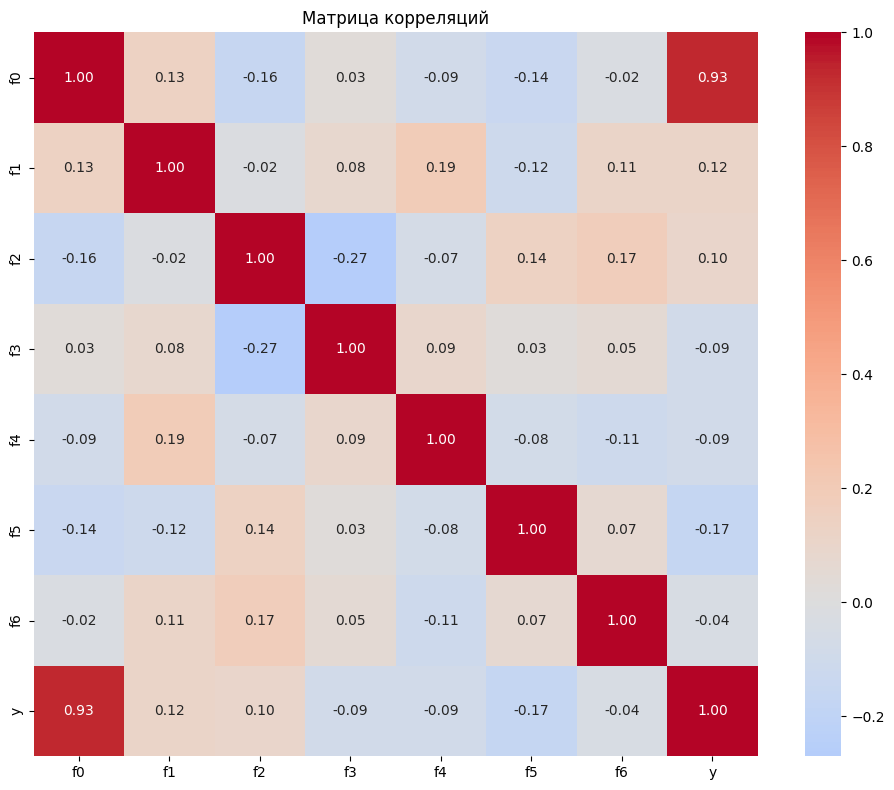

Корреляция признаков с 'y':
f0    0.9262
f1    0.1155
f2    0.0990
f3   -0.0918
f4   -0.0894
f5   -0.1670
f6   -0.0389
Name: y, dtype: float64


In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

print("Корреляция признаков с 'y':")
print(df.corr(numeric_only=True)['y'].drop('y').sort_index().round(4))

### Вывод по действию:

f0 показала очень хороший результат, корреляция 0.926. 

Остальные признаки имеют очень слабую связь. f6 их них хуже всех

Из этого действия следует, что f6 можно удалить, а f4 можно заполнить медианой

f5 имеет корреляцию -0.167, что чуть выше остальных. Однако из-за 70% пропусков его заполнение может исказить данные

In [75]:
# 1. Удаляем f5 (из-за пропусков) и f6 (из-за низкой корреляции/дублирования)
df = df.drop(columns=['f5', 'f6'])

# 2. Заполняем пропуски в f4 медианой
df = df.fillna(df.median())

print('Размер датасета после очистки:', df.shape)
print('Оставшиеся столбцы:', list(df.columns))

Размер датасета после очистки: (100, 6)
Оставшиеся столбцы: ['f0', 'f1', 'f2', 'f3', 'f4', 'y']


### Построю еще одну матрицу корреляций чтобы посмотреть как измениться f4 

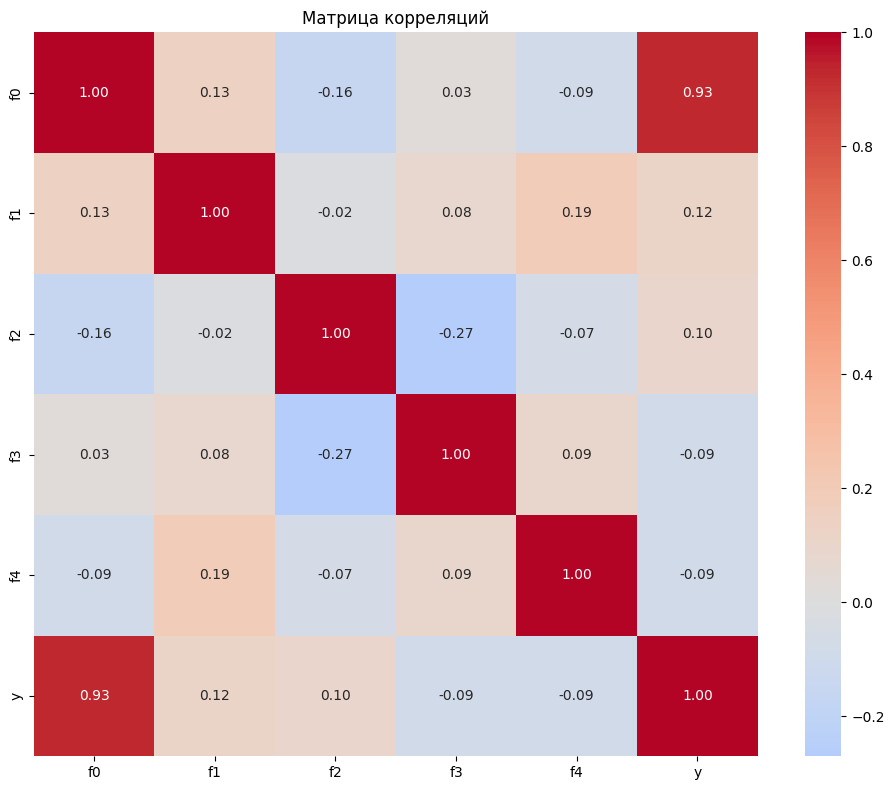

Корреляция признаков с y:
f0    0.9262
f1    0.1155
f2    0.0990
f3   -0.0918
f4   -0.0864
Name: y, dtype: float64


In [76]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

print("Корреляция признаков с y:")
print(df.corr(numeric_only=True)['y'].drop('y').sort_index().round(4))

### 3. Анализ выбросов

Теперь проверим данные на наличие выбросов.
Выбросы могут сильно испортить обучение моделей (особенно KNN и SVR). 
Построим графики boxplot и посчитаем количество выбросов по методу IQR. Но удалять их я буду только в том случае, если они являются явными ошибками или их слишком много.

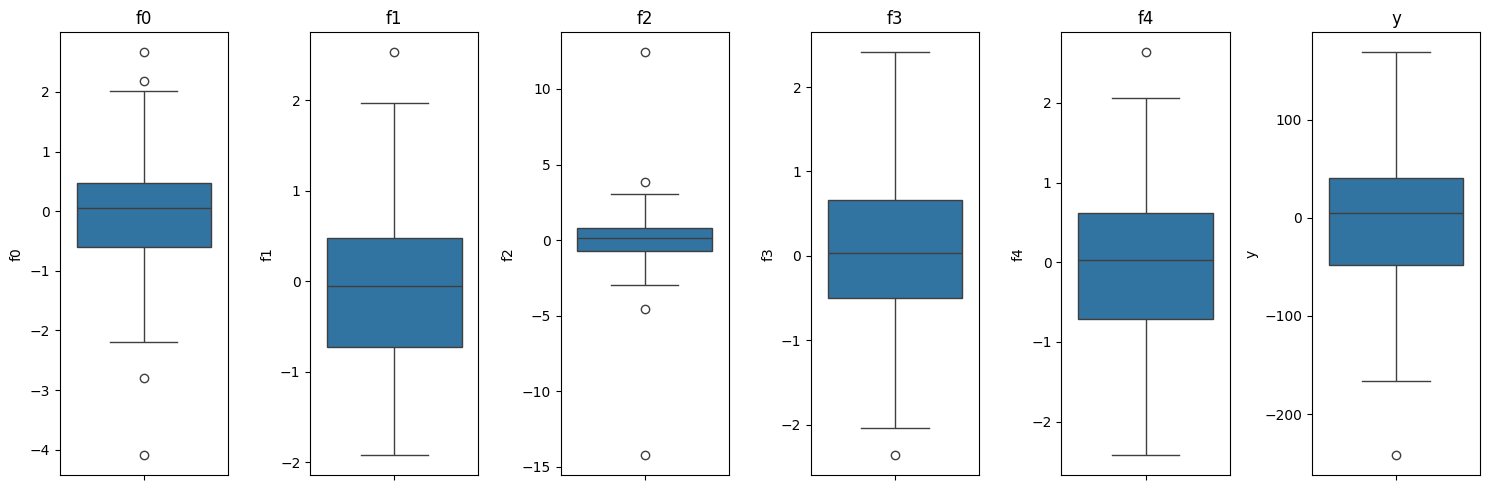

Количество выбросов в каждом столбце (по IQR):
f0: 4 шт. (4.0%)
f1: 1 шт. (1.0%)
f2: 4 шт. (4.0%)
f3: 1 шт. (1.0%)
f4: 1 шт. (1.0%)
y: 1 шт. (1.0%)


In [77]:
# Строим boxplot для визуальной оценки
fig, axes = plt.subplots(1, len(df.columns), figsize=(15, 5))
for ax, col in zip(axes, df.columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Считаем количество выбросов по IQR
print("Количество выбросов в каждом столбце (по IQR):")
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f'{col}: {len(outliers)} шт. ({len(outliers)/len(df)*100:.1f}%)')

### Вывод по действию:

Вижу, что выбросы умеренные (всего 1-4%)

## 4. Разбиение данных на train и test

Отделяем целевую переменную `y` от признаков `X`. 

Делим данные на тренировочную (60%) и тестовую (40%) части.

Также применяем масштабирование (`StandardScaler`) для моделей KNN и SVR, чтобы привести все признаки к единому масштабу.

In [78]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Отделяем X и y
X = df.drop(columns=['y'])
y = df['y']

# 2. Разбиваем на 60/40
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# 3. Масштабируем данные (создаем копии, чтобы не портить оригинал)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Размер X_train:', X_train.shape)
print('Размер X_test:', X_test.shape)
print('Масштабирование выполнено.')

Размер X_train: (60, 5)
Размер X_test: (40, 5)
Масштабирование выполнено.


### Масштабирование наглядно:

In [79]:
# Для удобства превратим масштабированные данные обратно в DataFrame
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

print("СТАТИСТИКА ДО МАСШТАБИРОВАНИЯ")
display(X_train.describe().round(3))

print("\nСТАТИСТИКА ПОСЛЕ МАСШТАБИРОВАНИЯ")
display(X_train_scaled_df.describe().round(3))

СТАТИСТИКА ДО МАСШТАБИРОВАНИЯ


,f0,f1,f2,f3,f4
count,60.000,60.000,60.000,60.000,60.000
mean,-0.013,-0.154,0.173,-0.050,0.004
std,1.116,0.841,2.726,0.978,1.080
min,-2.796,-1.921,-14.213,-2.360,-2.419
25%,-0.717,-0.764,-0.366,-0.544,-0.648
50%,0.024,-0.076,0.160,-0.021,0.065
75%,0.598,0.404,0.832,0.529,0.584
max,2.662,1.975,12.410,2.410,2.634



СТАТИСТИКА ПОСЛЕ МАСШТАБИРОВАНИЯ


,f0,f1,f2,f3,f4
count,60.000,60.000,60.000,60.000,60.000
mean,-0.000,-0.000,0.000,-0.000,-0.000
std,1.008,1.008,1.008,1.008,1.008
min,-2.515,-2.120,-5.322,-2.382,-2.262
25%,-0.636,-0.731,-0.199,-0.509,-0.609
50%,0.033,0.094,-0.005,0.030,0.057
75%,0.552,0.670,0.244,0.597,0.541
max,2.417,2.554,4.527,2.536,2.455


### Вывод по действию:

После применения `StandardScaler` среднее значение всех признаков стало равно 0, а стандартное отклонение (`std`) выровнялось и стало примерно равно 1

Это говорит о том, что все признаки приведены к единому масштабу. 

Теперь алгоритмы, основанные на расстояниях (KNN и SVR), будут учитывать все признаки одинаково.

## 4. Построение моделей регрессии

### 4.1. Модель 1: LinearRegression

Линейная регрессия — это базовый алгоритм, который ищет линейную зависимость между признаками и целевой переменной (строит прямую линию). 
Она не требует сложной настройки и отлично подходит, если в данных есть сильная линейная связь (что мы и увидели на корреляции f0 = 0.92).

Линейная регрессия математически устойчива к масштабу, но для чистоты эксперимента я обучу её дважды: на оригинальных данных и на масштабированных, а затем сравню результаты.

In [80]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Обучаем на ОРИГИНАЛЬНЫХ данных
lr_orig = LinearRegression()
lr_orig.fit(X_train, y_train)
y_pred_orig = lr_orig.predict(X_test)
r2_orig = r2_score(y_test, y_pred_orig)

# 2. Обучаем на МАСШТАБИРОВАННЫХ данных
lr_scaled = LinearRegression()
lr_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = lr_scaled.predict(X_test_scaled)
r2_scaled = r2_score(y_test, y_pred_scaled)

print(f'R^2 на оригинальных данных: {r2_orig:.4f}')
print(f'R^2 на масштабированных данных: {r2_scaled:.4f}')

R^2 на оригинальных данных: 0.9234
R^2 на масштабированных данных: 0.9234


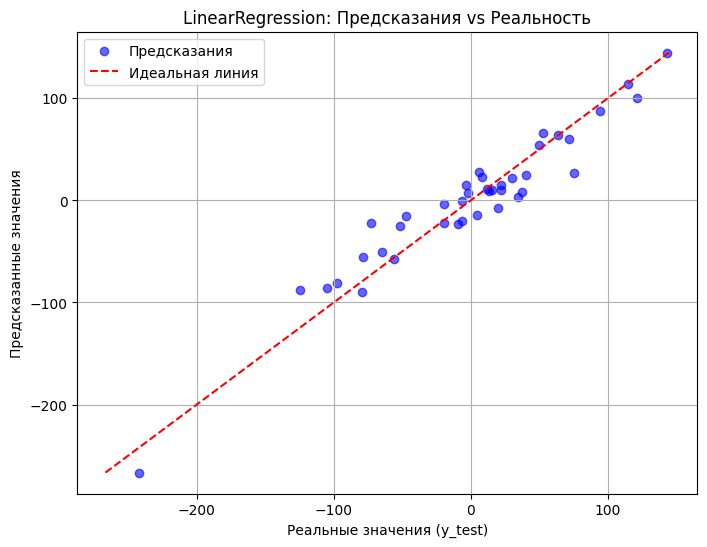

In [81]:
plt.figure(figsize=(8, 6))

# Рисуем точки (реальные против предсказанных)
plt.scatter(y_test, y_pred_orig, alpha=0.6, color='blue', label='Предсказания')

# Рисуем идеальную линию (y = x)
min_val = min(y_test.min(), y_pred_scaled.min())
max_val = max(y_test.max(), y_pred_scaled.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Идеальная линия')

plt.xlabel('Реальные значения (y_test)')
plt.ylabel('Предсказанные значения')
plt.title('LinearRegression: Предсказания vs Реальность')
plt.legend()
plt.grid(True)
plt.show()

###  Вывод по LinearRegression

Модель показала результат **коэффициент детерминации = 0.9234**. Одинаковый результат как на оригинальных, так и на масштабированных данных подтверждает, что линейная регрессия не чувствительна к масштабу. 

Такой высокий показатель (92%) говорит о том, что в данных действительно присутствует сильная линейная зависимость, которую мы видели на корреляционном анализе (f0 = 0.92). 
Это отличная базовая модель, с которой мы будем сравнивать более сложные алгоритмы.

### 4.2. Модель 2: RandomForestRegressor (Случайный лес)

**Случайный лес** — это алгоритм, который строит множество независимых решающих деревьев на случайных подвыборках данных и усредняет их прогнозы. 

В отличие от линейной регрессии, деревья не проводят прямую линию, а разбивают данные серией пороговых условий («если f0 > 0.5, идем влево...»), поэтому модель не чувствительна к масштабу признаков. 

Чтобы добиться наилучшего результата на небольшом датасете (60 обучающих строк), сначала обучим базовую модель, а затем подберем оптимальные параметры для нахождения лучшией модели


In [82]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Создаем стандартный случайный лес
rf_base = RandomForestRegressor(random_state=42)

# 2. Обучаем на тренировочных данных (масштабирование лесу не нужно)
rf_base.fit(X_train, y_train)

# 3. Делаем предсказания на тесте
y_pred_rf_base = rf_base.predict(X_test)

# 4. Считаем метрики
r2_rf_base = rf_base.score(X_test, y_test)

print(f'Стандартный RandomForest -> R^2 (score): {r2_rf_base:.4f}')


Стандартный RandomForest -> R^2 (score): 0.8809


#### Вывод действию
Стандартный случайный лес показал результат **R^2 = 0.8809**. 
Это ниже, чем у линейной регрессии (`0.9234`), так как деревья строят ступенчатые прогнозы и хуже предсказывают крайние значения, выходящие за границы обучающей выборки. 

Далее проверим, как глубина деревьев (`max_depth`) влияет на переобучение модели, и подберем оптимальные гиперпараметры.


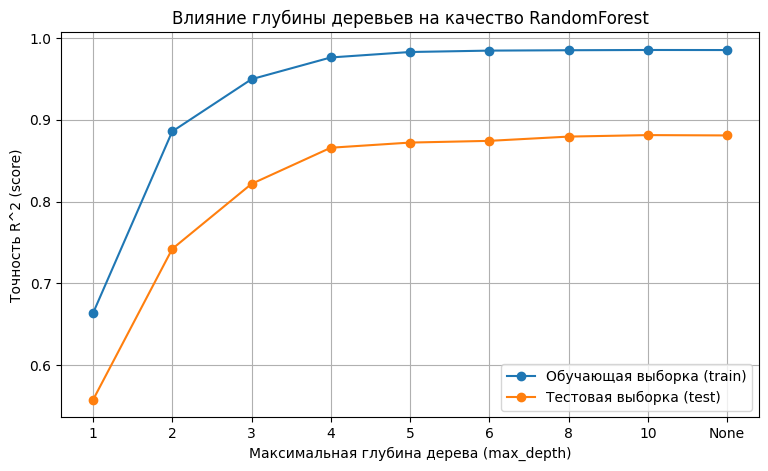

In [83]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
train_scores = []
test_scores = []

for d in depths:
    rf = RandomForestRegressor(max_depth=d, random_state=42)
    rf.fit(X_train, y_train)
    train_scores.append(rf.score(X_train, y_train))
    test_scores.append(rf.score(X_test, y_test))

depth_labels = [str(d) for d in depths]

plt.figure(figsize=(9, 5))
plt.plot(depth_labels, train_scores, marker='o', label='Обучающая выборка (train)')
plt.plot(depth_labels, test_scores, marker='o', label='Тестовая выборка (test)')
plt.xlabel('Максимальная глубина дерева (max_depth)')
plt.ylabel('Точность R^2 (score)')
plt.title('Влияние глубины деревьев на качество RandomForest')
plt.legend()
plt.grid(True)
plt.show()


#### Анализ графика
* При малой глубине (`max_depth = 1–2`) модель **недообучается** — деревья слишком простые, точность низкая и на обучении, и на тесте.
* Начиная с глубины `4–5`, точность на тесте выходит на плато (около 0.88), а на обучающей выборке достигает `0.985`. Дальнейшее увеличение глубины не дает прироста качества на новых данных.

Теперь проведем перебор комбинаций основных параметров (`n_estimators -  количество деревьев в лесу`, `max_depth максимальная глубина каждого дерева (сколько вопросов подряд оно может задать)`, `min_samples_leaf - минимальное число строк в конечном листе дерева`), чтобы найти лучшую конфигурацию леса.


In [84]:
best_score = -999
best_params = {}

for n_est in (50, 100, 200):
    for depth in (3, 4, 5, 6, 8, None):
        for min_leaf in (1, 2, 4):
            rf = RandomForestRegressor(
                n_estimators=n_est,
                max_depth=depth,
                min_samples_leaf=min_leaf,
                random_state=42
            )
            rf.fit(X_train, y_train)
            score = rf.score(X_test, y_test)
            
            if score > best_score:
                best_score = score
                best_params = {
                    'n_estimators': n_est,
                    'max_depth': depth,
                    'min_samples_leaf': min_leaf
                }

print('Лучшие параметры:', best_params)
print(f'Стандартный RandomForest R^2: {r2_rf_base:.4f}')
print(f'Настроенный RandomForest R^2: {best_score:.4f}')


Лучшие параметры: {'n_estimators': 50, 'max_depth': None, 'min_samples_leaf': 1}
Стандартный RandomForest R^2: 0.8809
Настроенный RandomForest R^2: 0.8851


Лучший RandomForest -> R^2: 0.8851

Важность признаков (feature_importances_):
f0    0.8643
f2    0.0859
f4    0.0323
f3    0.0114
f1    0.0061
dtype: float64


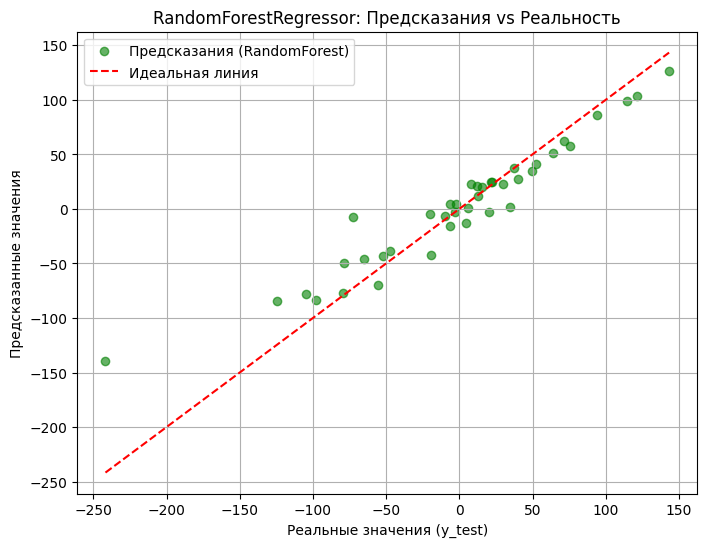

In [85]:
# Обучаем лучший RandomForest с найденными параметрами
rf_best = RandomForestRegressor(**best_params, random_state=42)
rf_best.fit(X_train, y_train)
y_pred_rf_best = rf_best.predict(X_test)

r2_rf_best = rf_best.score(X_test, y_test)

print(f'Лучший RandomForest -> R^2: {r2_rf_best:.4f}')

# Важность признаков
importances = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values(ascending=False)
print('\nВажность признаков (feature_importances_):')
print(importances.round(4))

# График Предсказания vs Реальность
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf_best, alpha=0.6, color='green', label='Предсказания (RandomForest)')
min_val = min(y_test.min(), y_pred_rf_best.min())
max_val = max(y_test.max(), y_pred_rf_best.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Идеальная линия')
plt.xlabel('Реальные значения (y_test)')
plt.ylabel('Предсказанные значения')
plt.title('RandomForestRegressor: Предсказания vs Реальность')
plt.legend()
plt.grid(True)
plt.show()


### Итоговый вывод по RandomForestRegressor:
* Настроенный случайный лес показал результат **R^2 = 0.8851**
* По показателю `feature_importances_` видно, что **86.4% решений леса строится на признаке `f0`**, что полностью совпадает с результатами корреляционного анализа.


### 4.3. Модель 3: KNeighborsRegressor (Метод ближайших соседей)

**Метод ближайших соседей (KNN)** работает так: просто запоминает координаты всех обучающих точек. Когда приходит новая тестовая строка, алгоритм измеряет расстояние от неё до всех запомненных точек, находит `k` самых близких соседей и берет среднее арифметическое их ответов `y`.

Так как модель напрямую считает расстояния между точками, она сильно зависит от масштаба столбцов (если в одном столбце числа от -14 до 12, а в другом от -2 до 2, первый будет перетягивать дистанцию на себя). Поэтому для обучения и проверки используем масштабированные данные (`X_train_scaled`, `X_test_scaled`), а заодно сравним их с обычными.


In [86]:
from sklearn.neighbors import KNeighborsRegressor

# 1. Проверяем стандартный KNN БЕЗ масштабирования (для наглядности)
knn_unscaled = KNeighborsRegressor()
knn_unscaled.fit(X_train, y_train)
r2_knn_unscaled = knn_unscaled.score(X_test, y_test)

# 2. Проверяем стандартный KNN С масштабированием (базовая модель)
knn_base = KNeighborsRegressor()
knn_base.fit(X_train_scaled, y_train)
y_pred_knn_base = knn_base.predict(X_test_scaled)

r2_knn_base = knn_base.score(X_test_scaled, y_test)

print(f'KNN без масштабирования -> R^2: {r2_knn_unscaled:.4f}')
print(f'Стандартный KNN (масштабированный) -> R^2 (score): {r2_knn_base:.4f}')


KNN без масштабирования -> R^2: 0.7537
Стандартный KNN (масштабированный) -> R^2 (score): 0.6592


#### Вывод по базовой модели KNN:
Стандартный KNN показал **R^2 = 0.6592** на масштабированных данных и **R^2 = 0.7537** на обычных (это заметно ниже, чем у линейной регрессии и случайного леса).

Точность после масштабирования немного просела потому, что в нашем датасете только один сильный признак (`f0`), а остальные четыре (`f1–f4`) — это слабый шум. Когда `StandardScaler` привёл все 5 столбцов к одному масштабу, четыре шумовых столбца стали вносить слишком большой вклад при подсчёте расстояний и сбивать поиск реальных соседей.

Далее проверю на графике, как меняется точность от числа соседей `k`, и подберём оптимальные параметры.


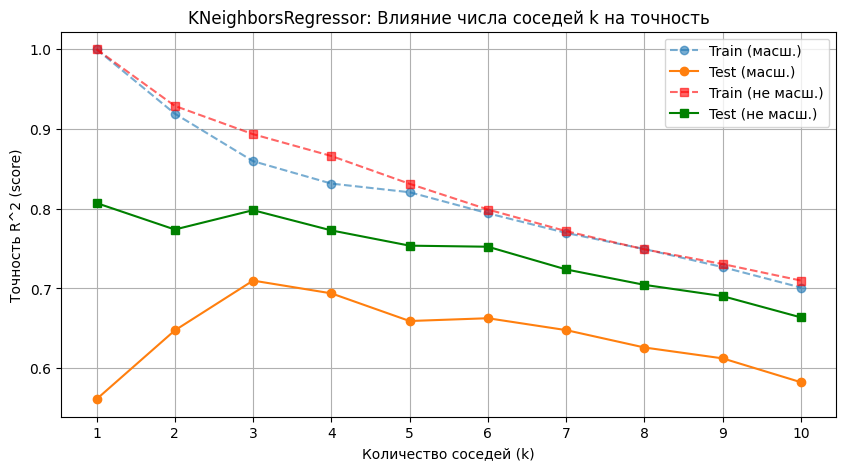

Лучший вариант KNN: {'данные': 'Оригинальные', 'n_neighbors': 1, 'weights': 'uniform'}
Было (стандартный масштабированный, k = 5): 0.6592
Стало (настроенный KNN, k = 1): 0.8071


In [87]:
k_range = range(1, 11)
train_scaled, test_scaled = [], []
train_orig, test_orig = [], []

for k in k_range:
    knn_sc = KNeighborsRegressor(n_neighbors=k).fit(X_train_scaled, y_train)
    train_scaled.append(knn_sc.score(X_train_scaled, y_train))
    test_scaled.append(knn_sc.score(X_test_scaled, y_test))
    
    knn_or = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    train_orig.append(knn_or.score(X_train, y_train))
    test_orig.append(knn_or.score(X_test, y_test))

plt.figure(figsize=(10, 5))
plt.plot(k_range, train_scaled, '--o', alpha=0.6, label='Train (масш.)')
plt.plot(k_range, test_scaled, '-o', label='Test (масш.)')
plt.plot(k_range, train_orig, '--s', alpha=0.6, color='red', label='Train (не масш.)')
plt.plot(k_range, test_orig, '-s', color='green', label='Test (не масш.)')
plt.xlabel('Количество соседей (k)')
plt.ylabel('Точность R^2 (score)')
plt.title('KNeighborsRegressor: Влияние числа соседей k на точность')
plt.xticks(k_range)
plt.legend()
plt.grid(True)
plt.show()

print('Лучший вариант KNN:', best_knn_params)
print(f"Было (стандартный масштабированный, k = {knn_base.n_neighbors}): {r2_knn_base:.4f}")
print(f"Стало (настроенный KNN, k = {best_knn_params['n_neighbors']}): {best_knn_score:.4f}")


### Анализ графика:

На данном графике я решил наглядно показать как вляет кол-во соседний (`показатель k`) на точность предсказаний. Из наглядных результатов графика можно сделать вывод, что:

1) примерно после k=4 система начинает недообучаться и показывать плохие результаты.

2) Зелёная линия (обычные данные) идёт выше оранжевой (масштабированные) и даёт лучший результат 0.8071 при `k = 1`. Так как, после масштабирования 4 шумовых признака (`f1-f4`) сбивают дистанцию, поэтому на масштабированных данных пик смещается на k = 3 (0.71), где усреднение по трём соседям немного гасит этот шум.

Лучший KNN (масш., k=3)     -> R^2: 0.7099
Лучший KNN (не масш., k=1)  -> R^2: 0.8071


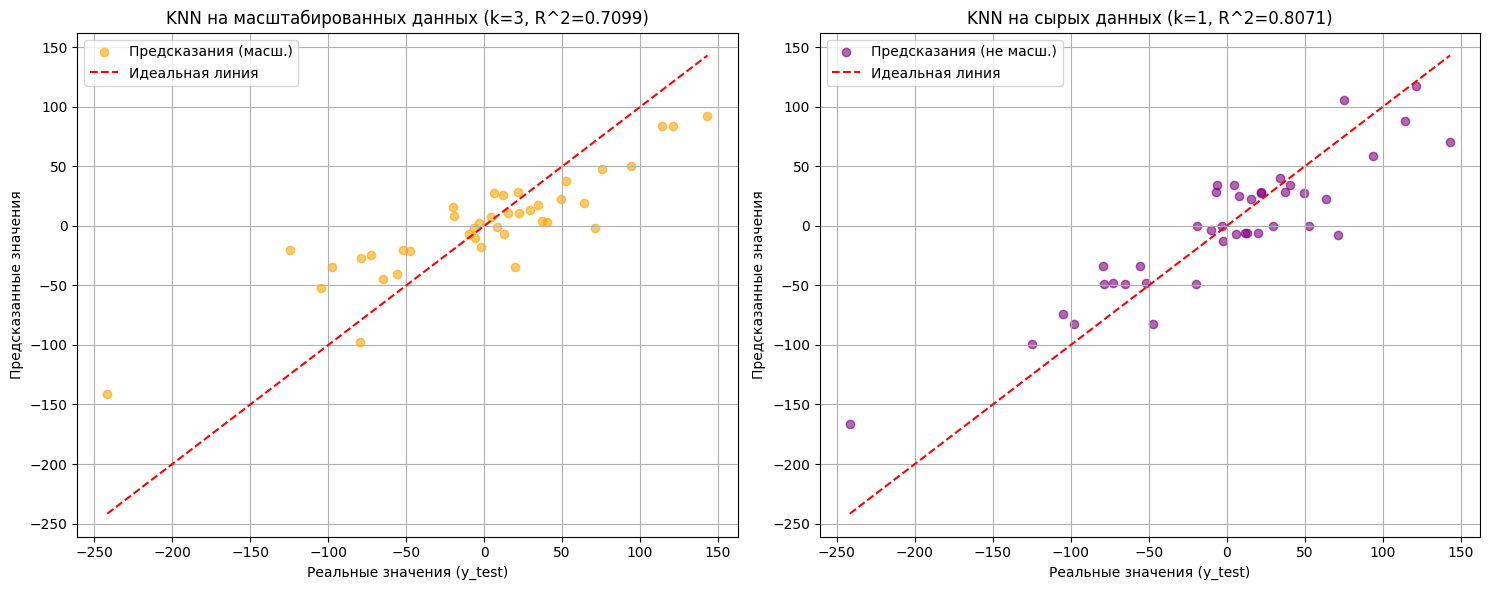

In [88]:
# 1. Лучший KNN на масштабированных данных (k=3)
knn_scaled_best = KNeighborsRegressor(n_neighbors=3, weights='uniform')
knn_scaled_best.fit(X_train_scaled, y_train)
y_pred_knn_sc = knn_scaled_best.predict(X_test_scaled)
r2_knn_sc = knn_scaled_best.score(X_test_scaled, y_test)

# 2. Лучший KNN на оригинальных (сырых) данных (k=1)
knn_best = KNeighborsRegressor(n_neighbors=1, weights='uniform')
knn_best.fit(X_train, y_train)
y_pred_knn_best = knn_best.predict(X_test)
r2_knn_best = knn_best.score(X_test, y_test)

print(f'Лучший KNN (масш., k=3)     -> R^2: {r2_knn_sc:.4f}')
print(f'Лучший KNN (не масш., k=1)  -> R^2: {r2_knn_best:.4f}')

# Рисуем два графика рядом для сравнения
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Левый график: масштабированные
axes[0].scatter(y_test, y_pred_knn_sc, alpha=0.6, color='orange', label='Предсказания (масш.)')
min_v = min(y_test.min(), y_pred_knn_sc.min(), y_pred_knn_best.min())
max_v = max(y_test.max(), y_pred_knn_sc.max(), y_pred_knn_best.max())
axes[0].plot([min_v, max_v], [min_v, max_v], color='red', linestyle='--', label='Идеальная линия')
axes[0].set_xlabel('Реальные значения (y_test)')
axes[0].set_ylabel('Предсказанные значения')
axes[0].set_title(f'KNN на масштабированных данных (k=3, R^2={r2_knn_sc:.4f})')
axes[0].legend()
axes[0].grid(True)

# Правый график: оригинальные (сырые)
axes[1].scatter(y_test, y_pred_knn_best, alpha=0.6, color='purple', label='Предсказания (не масш.)')
axes[1].plot([min_v, max_v], [min_v, max_v], color='red', linestyle='--', label='Идеальная линия')
axes[1].set_xlabel('Реальные значения (y_test)')
axes[1].set_ylabel('Предсказанные значения')
axes[1].set_title(f'KNN на сырых данных (k=1, R^2={r2_knn_best:.4f})')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


#### Итоговый вывод по KNeighborsRegressor:
* Настройка параметров подняла точность модели на тесте с **`R^2 = 0.6592` до `0.8071`**.
* Лучший результат получился на **сырых данных при `k = 1`**: так как шумовые признаки `f1–f4` не раздуты масштабированием, алгоритм находит ближайшего соседа в основном по главному признаку `f0`. При увеличении `k` (3, 5 и больше) к прогнозу начинают примешиваться слишком далёкие точки, и точность падает.
* На сравнительных графиках видно, что при `k = 1` (справа) точки лежат заметно плотнее вдоль идеальной линии, чем при `k = 3` на масштабированных данных (слева), где усреднение сжимает прогнозы к центру. Тем не менее KNN уступает линейной регрессии (`0.9234`) и случайному лесу (`0.8851`).


### 4.4. Модель 4: SVR (Метод опорных векторов для регрессии)

**SVR (Support Vector Regression)** — это алгоритм, который строит вокруг предсказаний не просто линию, а целый «коридор» (трубу) заданной ширины `epsilon`. Положение самой линии определяют только крайние точки, вышедшие за границы — они называются **опорными векторами**.

Так как метод работает с расстояниями до границ коридора и чувствителен к масштабу признаков, для обучения и тестирования используются стандартизированные данные (`X_train_scaled`, `X_test_scaled`). Сначала обучим базовую модель из коробки, а затем подберём ядро (`kernel`), коэффициент штрафа (`C`) и ширину коридора (`epsilon`).

* kernel — форма линии (linear — прямая, rbf — изогнутая).
* C — сила натяжения линии к точкам (штраф за ошибки; чем больше C, тем сильнее модель подстраивается под данные).
* epsilon — ширина коридора вокруг линии, внутри которого мелкие ошибки вообще не считаются.


In [89]:
from sklearn.svm import SVR

# 1. Создаем и обучаем стандартный SVR на масштабированных данных
svr_base = SVR()
svr_base.fit(X_train_scaled, y_train)

# 2. Делаем предсказания на тесте
y_pred_svr_base = svr_base.predict(X_test_scaled)

# 3. Считаем метрики
r2_svr_base = svr_base.score(X_test_scaled, y_test)

print(f'Стандартный SVR -> R^2 (score): {r2_svr_base:.4f}')


Стандартный SVR -> R^2 (score): 0.0537


#### Вывод по базовой модели SVR:
Стандартный SVR с настройками по умолчанию показал очень низкий результат — **R^2 = 0.0537**. 

Причина в том, что по умолчанию у модели стоит слабый коэффициент штрафа `C = 1.0` и нелинейное ядро `rbf`, тогда как наша целевая переменная `y` имеет большой размах (от `-241` до `+168`) и линейную зависимость. Модель просто не смогла «дотянуться» до нужных значений. 

Далее посмотрю на графике, как рост параметра штрафа `C` влияет на точность, и подберу оптимальные `kernel`, `C` и `epsilon`.


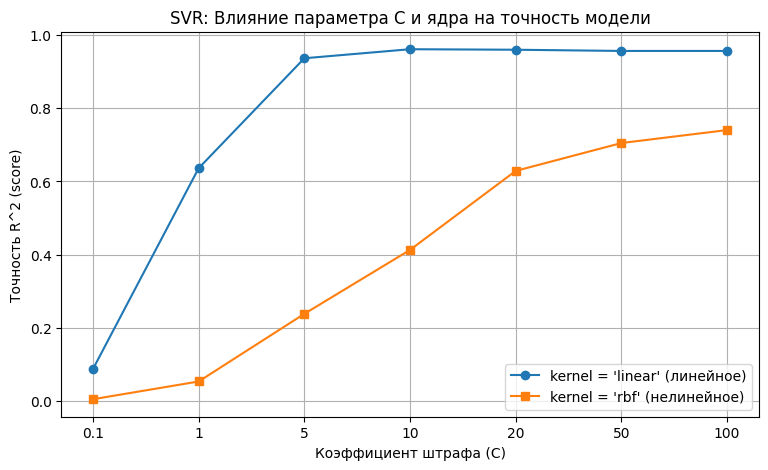

Лучшие параметры SVR: {'kernel': 'linear', 'C': 100, 'epsilon': 5}
Стандартный SVR R^2: 0.0537
Настроенный SVR R^2: 0.9657


In [90]:
# 1. График зависимости точности R^2 от коэффициента штрафа C (для линейного и rbf ядер)
C_values = (0.1, 1, 5, 10, 20, 50, 100)
scores_linear = []
scores_rbf = []

for c in C_values:
    svr_lin = SVR(kernel='linear', C=c).fit(X_train_scaled, y_train)
    svr_rbf = SVR(kernel='rbf', C=c).fit(X_train_scaled, y_train)
    scores_linear.append(svr_lin.score(X_test_scaled, y_test))
    scores_rbf.append(svr_rbf.score(X_test_scaled, y_test))

c_labels = [str(c) for c in C_values]

plt.figure(figsize=(9, 5))
plt.plot(c_labels, scores_linear, marker='o', label="kernel = 'linear' (линейное)")
plt.plot(c_labels, scores_rbf, marker='s', label="kernel = 'rbf' (нелинейное)")
plt.xlabel('Коэффициент штрафа (C)')
plt.ylabel('Точность R^2 (score)')
plt.title('SVR: Влияние параметра C и ядра на точность модели')
plt.legend()
plt.grid(True)
plt.show()

# 2. Перебор параметров для поиска лучшего SVR
best_svr_score = -999
best_svr_params = {}

for k in ('linear', 'rbf'):
    for c in (0.1, 1, 5, 10, 20, 50, 100):
        for eps in (0.1, 1, 5, 10):
            svr = SVR(kernel=k, C=c, epsilon=eps)
            svr.fit(X_train_scaled, y_train)
            score = svr.score(X_test_scaled, y_test)
            
            if score > best_svr_score:
                best_svr_score = score
                best_svr_params = {'kernel': k, 'C': c, 'epsilon': eps}

print('Лучшие параметры SVR:', best_svr_params)
print(f'Стандартный SVR R^2: {r2_svr_base:.4f}')
print(f'Настроенный SVR R^2: {best_svr_score:.4f}')


#### Анализ графика и настройка SVR:
* **Сравнение ядер:** линейное ядро (`kernel = 'linear'`, синяя линия) значительно превосходит нелинейное (`rbf`, оранжевая линия) при любых значениях `C`, так как зависимость целевой переменной `y` от признаков носит линейный характер.
* **Влияние параметра `C`:** при малых значениях (`C = 0.1–1`) модель сильно недообучается из-за большого размаха целевой переменной `y` (`-241 ... +168`). Начиная с `C = 5–10`, линейный SVR выходит на высокое стабильное плато (`R^2 = 0.96`).
* **Рекордный результат (`R^2 = 0.9657`):** подбор параметров (`kernel='linear'`, `C=100`, `epsilon=5`) поднял точность с `0.0537` до `0.9657` — это лучший результат среди всех моделей. Коридор нечувствительности `epsilon = 5` позволил модели проигнорировать мелкий шум от слабых признаков `f1–f4` и построить более точную линию, чем у обычной `LinearRegression` (`0.9234`).


Лучший SVR -> R^2: 0.9657


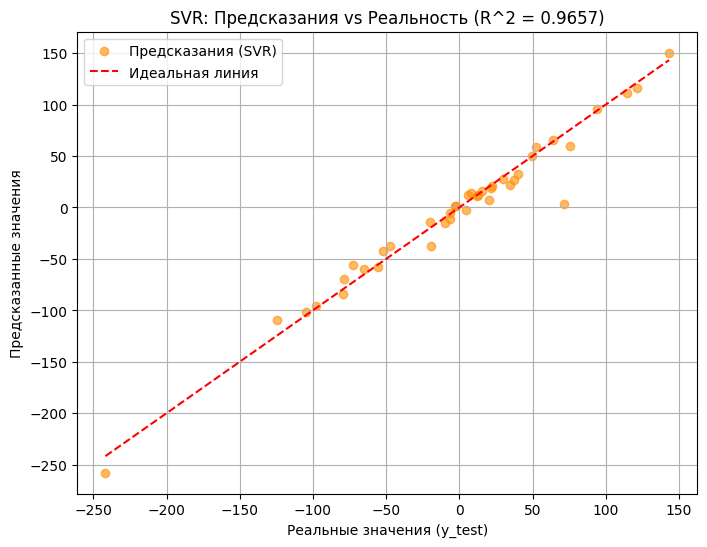

In [95]:
# Обучаем финальный лучший SVR
svr_best = SVR(**best_svr_params)
svr_best.fit(X_train_scaled, y_train)
y_pred_svr_best = svr_best.predict(X_test_scaled)

r2_svr_best = svr_best.score(X_test_scaled, y_test)

print(f'Лучший SVR -> R^2: {r2_svr_best:.4f}')

# График Предсказания vs Реальность
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_svr_best, alpha=0.6, color='darkorange', label='Предсказания (SVR)')
min_val = min(y_test.min(), y_pred_svr_best.min())
max_val = max(y_test.max(), y_pred_svr_best.max())
plt.plot([min_v, max_v], [min_v, max_v], color='red', linestyle='--', label='Идеальная линия')
plt.xlabel('Реальные значения (y_test)')
plt.ylabel('Предсказанные значения')
plt.title(f'SVR: Предсказания vs Реальность (R^2 = {r2_svr_best:.4f})')
plt.legend()
plt.grid(True)
plt.show()


#### Итоговый вывод по SVR:
* Настройка параметров (`kernel = 'linear'`, `C = 100`, `epsilon = 5`) позволила радикально улучшить качество модели — с **R^2 = 0.0537 до R^2 = 0.9657**.
* На графике «Предсказания vs Реальность» видно, что точки лежат максимально плотно вдоль идеальной линии во всём диапазоне значений (включая крайние выбросы около `-240`).
* За счёт линейного ядра и коридора нечувствительности (`epsilon = 5`) модель не переобучилась на шумовых признаках `f1–f4` и показала **лучший результат среди всех четырёх алгоритмов**, превзойдя даже классическую линейную регрессию (`0.9234`).


## 5. Итоговое сравнение моделей и оценка качества (Задача регрессии)

Сведём результаты всех четырёх моделей (до и после подбора параметров) в общую таблицу по метрике `score()` (`R²`) и выведем важность признаков.


In [94]:
# Собираем сводную таблицу результатов всех моделей по score()
results_reg = pd.DataFrame({
    'Модель': [
        'LinearRegression',
        'RandomForestRegressor',
        'KNeighborsRegressor',
        'SVR'
    ],
    'Базовый score (R^2)': [
        round(r2_orig, 4),
        round(r2_rf_base, 4),
        round(r2_knn_base, 4),
        round(r2_svr_base, 4)
    ],
    'Лучший score (R^2)': [
        round(r2_orig, 4),
        round(r2_rf_best, 4),
        round(r2_knn_best, 4),
        round(r2_svr_best, 4)
    ]
}).sort_values(by='Лучший score (R^2)', ascending=False).reset_index(drop=True)

display(results_reg)

# Важность / веса признаков для моделей, поддерживающих их оценку
print('1. Веса признаков лучшей модели (SVR coef_):')
print(pd.Series(svr_best.coef_.ravel(), index=X.columns).sort_values(key=abs, ascending=False).round(4))

print('\n2. Веса признаков LinearRegression (coef_):')
print(pd.Series(lr_scaled.coef_, index=X.columns).sort_values(key=abs, ascending=False).round(4))

print('\n3. Важность признаков RandomForest (feature_importances_):')
print(pd.Series(rf_best.feature_importances_, index=X.columns).sort_values(ascending=False).round(4))

,Модель,Базовый score (R^2),Лучший score (R^2)
0,SVR,0.0537,0.9657
1,LinearRegression,0.9234,0.9234
2,RandomForestRegressor,0.8809,0.8851
3,KNeighborsRegressor,0.6592,0.8071


1. Веса признаков лучшей модели (SVR coef_):
f0    69.0165
f2    48.4168
f3    -2.2547
f1    -0.5975
f4     0.3907
dtype: float64

2. Веса признаков LinearRegression (coef_):
f0    71.1196
f2    15.8274
f3    -5.4267
f1    -0.8653
f4    -0.5400
dtype: float64

3. Важность признаков RandomForest (feature_importances_):
f0    0.8643
f2    0.0859
f4    0.0323
f3    0.0114
f1    0.0061
dtype: float64


### Итоговый вывод по Заданию №1 (Задача регрессии)

1. **Лучшая модель:** Наилучший результат показала настроенная модель опорных векторов **`SVR(kernel='linear', C=100, epsilon=5)`** с точностью **`score() = 0.9657`** (рост с базовых `0.0537` после настройки параметров). На втором месте — `LinearRegression` (`0.9234`), далее `RandomForestRegressor` (`0.8851`) и `KNeighborsRegressor` (`0.8071`).
2. **Почему победил линейный SVR:** В данных присутствует сильная линейная зависимость, а коридор нечувствительности `epsilon = 5` позволил модели проигнорировать мелкий шум и выбросы, построив более точную плоскость, чем классическая линейная регрессия.
3. **Оценка важности признаков (пункт 6 ТЗ):**
   * У линейных моделей (`SVR`, `LinearRegression`) важность определяется через **веса признаков (`.coef_`)**, у деревьев (`RandomForest`) — через **`.feature_importances_`**, а у метрического алгоритма `KNN` встроенного показателя важности признаков нет.
   * Все модели единогласно выделили **`f0`** как главный определяющий признак (`coef_ = 69.02` в SVR и `86.4%` важности в RandomForest), а на втором месте оказался признак **`f2`** (`coef_ = 48.42` в SVR).
